# Postprocessing

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
# %load_ext line_profiler
# %load_ext snakeviz
%autoreload 2

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import corner

import pickle

import enterprise
from enterprise.pulsar import Pulsar
import enterprise.signals.parameter as parameter
from enterprise.signals import utils
from enterprise.signals import signal_base
from enterprise.signals import selections
from enterprise.signals.selections import Selection
from enterprise.signals import white_signals
from enterprise.signals import gp_signals
from enterprise.signals import deterministic_signals
import enterprise.constants as const

from enterprise_extensions import deterministic

from scipy.stats import norm

import libstempo as T2
import libstempo.toasim as LT
import libstempo.plot as LP

import glob
import json
import h5py
# import healpy as hp
import scipy.constants as sc
import emcee

from numba.typed import List

In [5]:
#load psr pickles

#make sure this points to the same pickled pulsars we used for the MCMC
data_pkl = '../../data/NG15_5psr.pkl'

#with open('nanograv_11yr_psrs_old.pkl', 'rb') as psr_pkl:
with open(data_pkl, 'rb') as psr_pkl:
    psrs = pickle.load(psr_pkl)
    
print(len(psrs))

5


In [6]:
#load psr names only if we want to save RAM
# class psr_name:
#     def __init__(self, name):
#         self.name = name

# psrListFile = "../data/quickCW_test_psrlist.txt"

# psrs = []
# with open(psrListFile, 'r') as fff:
#     for line in fff:
#         psrname = line.strip()
#         #print(psrname)
#         psrs.append(psr_name(psrname))
        
print(len(psrs))
for i,psr in enumerate(psrs):
    print(str(i) + ": " + psr.name)

5
0: B1855+09
1: B1937+21
2: B1953+29
3: J0023+0923
4: J0030+0451


## Load run + general diagnostics

In [7]:
#load results from HDF5 file

hdf_file = "quickCW_test1.h5"

with h5py.File(hdf_file, 'r') as f:
    print(list(f.keys()))
    samples_cold = f['samples_cold'][0,::10,:]
    print(f['samples_cold'].dtype)
    #samples = f['samples_cold'][...]
    #log_likelihood = f['log_likelihood'][:,::10]
    print(f['log_likelihood'].dtype)
    log_likelihood = f['log_likelihood'][...]
    par_names = [x.decode('UTF-8') for x in list(f['par_names'])]
    acc_fraction = f['acc_fraction'][...]
    fisher_diag = f['fisher_diag'][...]

#print(acc_fraction)
#print(acc_fraction[:,:])
#print(samples.shape)
#samples_cold = np.copy(samples[0,:,::])
print(samples_cold.shape)
#print(par_names)

['T-ladder', 'acc_fraction', 'fisher_diag', 'log_likelihood', 'par_names', 'samples_cold', 'samples_freq']
float32
float64
(50000, 30)


Text(0, 0.5, 'Acceptance rate')

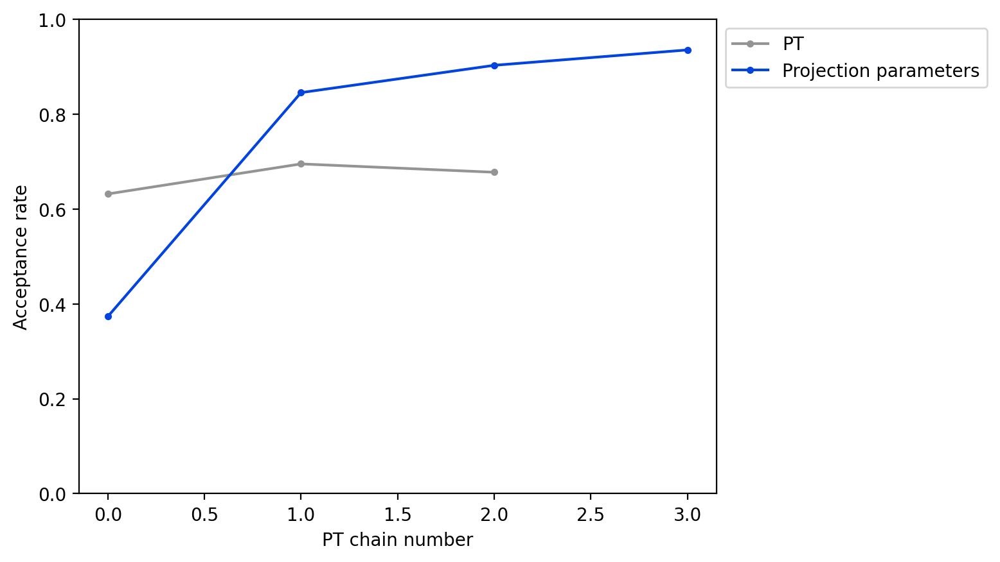

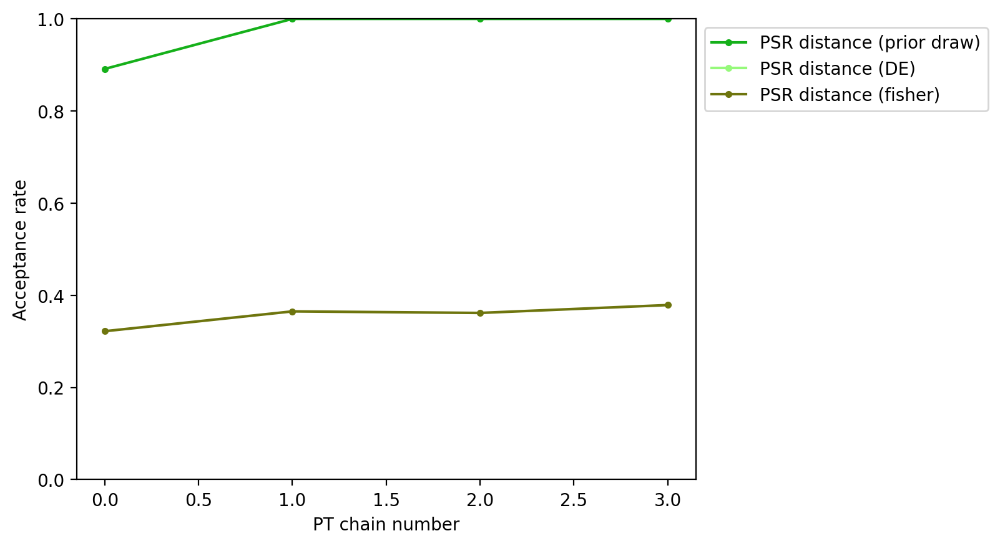

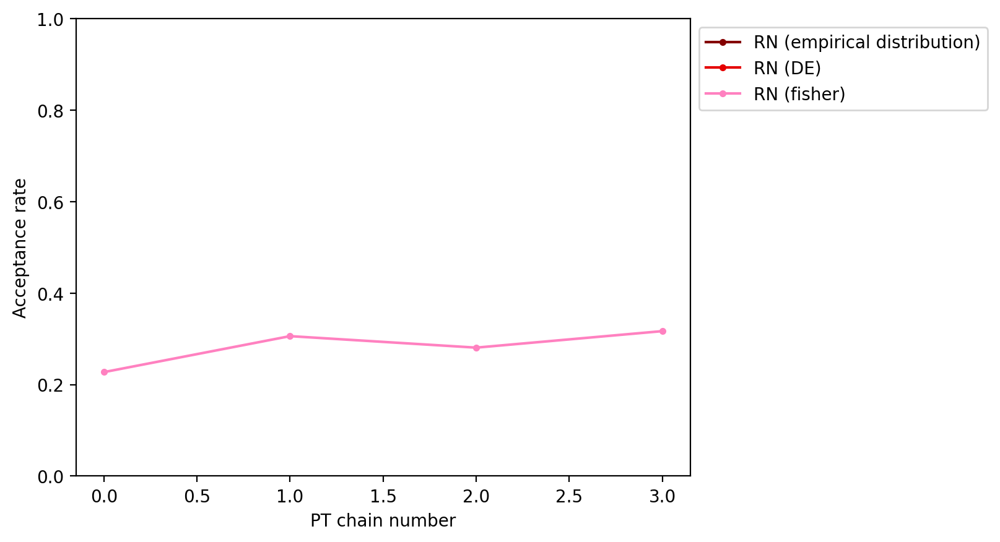

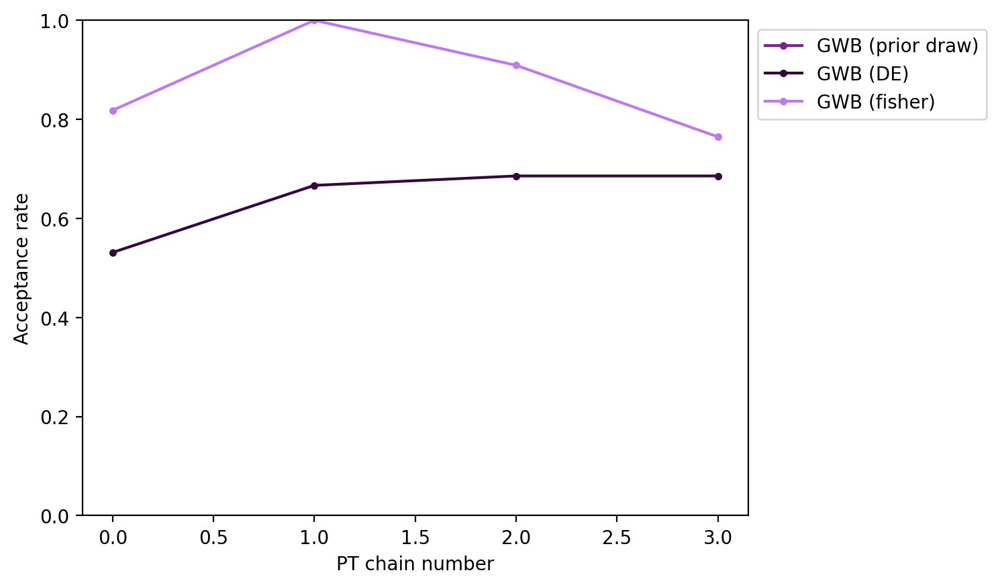

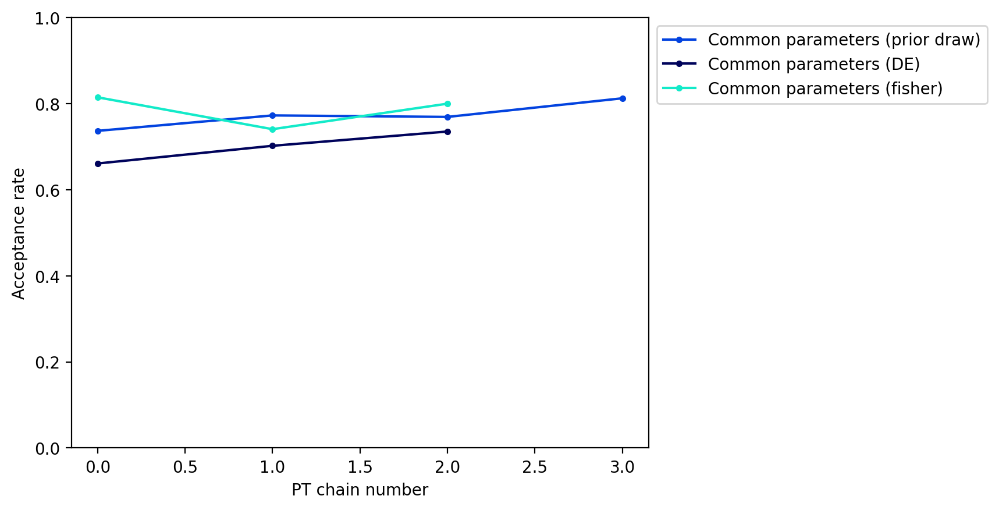

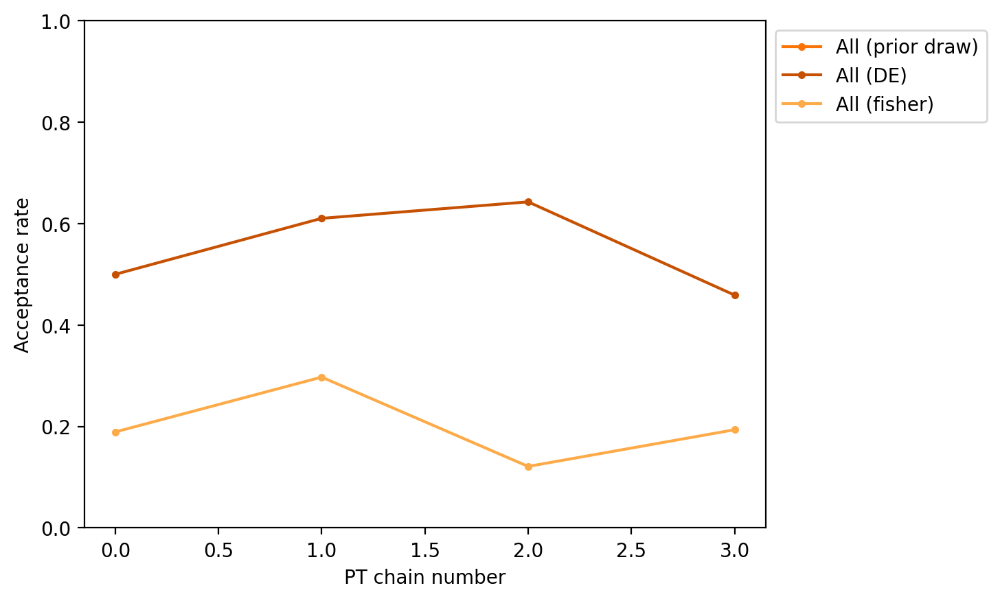

In [8]:
#Plot acceptance fraction for different kinds of steps as a function of PT chain - good for checking is run is okay

plt.figure(0)
plt.plot(acc_fraction[-2,:], color='xkcd:grey', ls='-', marker='.', label="PT")
plt.plot(acc_fraction[-1,:], color='xkcd:blue', ls='-', marker='.', label="Projection parameters")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.xlabel("PT chain number")
plt.ylabel("Acceptance rate")


plt.figure(1)
plt.plot(acc_fraction[1,:], color='xkcd:green', ls='-', marker='.', label="PSR distance (prior draw)")
plt.plot(acc_fraction[3,:], color='xkcd:light green', ls='-', marker='.', label="PSR distance (DE)")
plt.plot(acc_fraction[5,:], color='xkcd:olive', ls='-', marker='.', label="PSR distance (fisher)")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.xlabel("PT chain number")
plt.ylabel("Acceptance rate")


plt.figure(2)
plt.plot(acc_fraction[7,:], color='xkcd:dark red', ls='-', marker='.', label="RN (empirical distribution)")
plt.plot(acc_fraction[9,:], color='xkcd:red', ls='-', marker='.', label="RN (DE)")
plt.plot(acc_fraction[11,:], color='xkcd:pink', ls='-', marker='.', label="RN (fisher)")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.xlabel("PT chain number")
plt.ylabel("Acceptance rate")


plt.figure(3)
plt.plot(acc_fraction[13,:], color='xkcd:purple', ls='-', marker='.', label="GWB (prior draw)")
plt.plot(acc_fraction[15,:], color='xkcd:dark purple', ls='-', marker='.', label="GWB (DE)")
plt.plot(acc_fraction[17,:], color='xkcd:light purple', ls='-', marker='.', label="GWB (fisher)")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.xlabel("PT chain number")
plt.ylabel("Acceptance rate")

plt.figure(4)
plt.plot(acc_fraction[19,:], color='xkcd:blue', ls='-', marker='.', label="Common parameters (prior draw)")
plt.plot(acc_fraction[21,:], color='xkcd:dark blue', ls='-', marker='.', label="Common parameters (DE)")
plt.plot(acc_fraction[23,:], color='xkcd:aqua', ls='-', marker='.', label="Common parameters (fisher)")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.xlabel("PT chain number")
plt.ylabel("Acceptance rate")

plt.figure(5)
plt.plot(acc_fraction[25,:], color='xkcd:orange', ls='-', marker='.', label="All (prior draw)")
plt.plot(acc_fraction[27,:], color='xkcd:dark orange', ls='-', marker='.', label="All (DE)")
plt.plot(acc_fraction[29,:], color='xkcd:light orange', ls='-', marker='.', label="All (fisher)")
plt.ylim(0,1)
plt.legend(bbox_to_anchor=(1,1), loc="upper left")
plt.xlabel("PT chain number")
plt.ylabel("Acceptance rate")

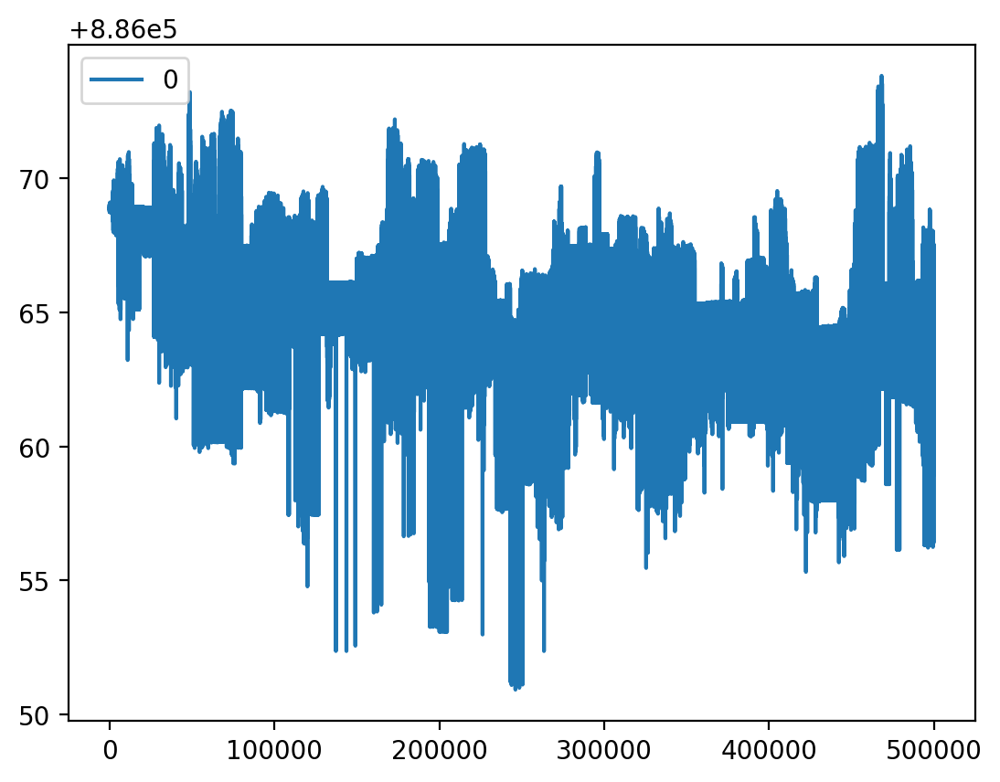

In [9]:
#plot the trace of the likelihood values to see if its sensible
for j in range(1):
    plt.plot(log_likelihood[j,10::1], label=str(j))
    
plt.legend()

(1e-07, 0.1)

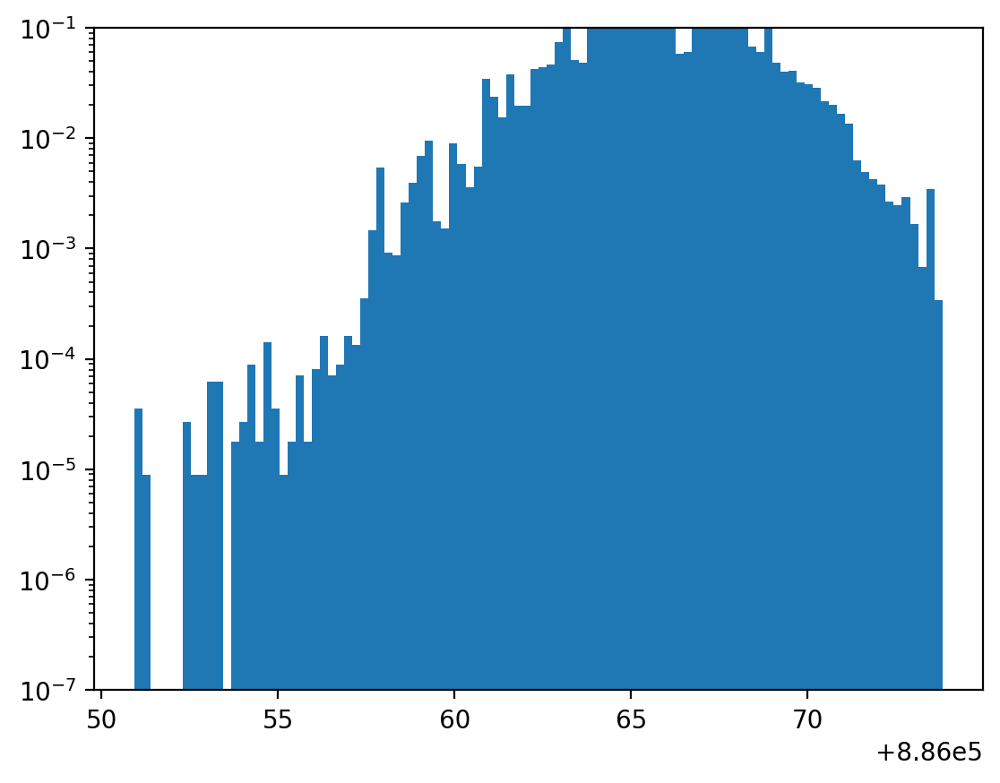

In [10]:
#also plot the histogram of likelihoods
_ = plt.hist(log_likelihood[0,10_000::1], density=True, bins=100)
plt.yscale('log')
#plt.xlim(3_302_770, 3_302_860)
plt.ylim(1e-7,1e-1)

In [21]:
#set up dictionary with true values of parameters
#set it to nan where not known

KPC2S = sc.parsec / sc.c * 1e3
SOLAR2S = sc.G / sc.c ** 3 * 1.98855e30

xxx = {"0_cos_gwtheta":np.nan,
       "0_cos_inc":np.nan,
       "0_gwphi":np.nan,
       "0_log10_dist":np.nan,
       "0_log10_fgw":np.nan,
       "0_log10_mc":np.nan,
       "0_phase0":np.nan,
       "0_psi":np.nan}

singwtheta = np.sin(np.arccos(xxx['0_cos_gwtheta']))
cosgwtheta = xxx['0_cos_gwtheta']
singwphi = np.sin(xxx["0_gwphi"])
cosgwphi = np.cos(xxx["0_gwphi"])
omhat = np.array([-singwtheta * cosgwphi, -singwtheta * singwphi, -cosgwtheta])

with open('../../data/15year_noise_dict.json', 'r') as fp:
        noisedict = json.load(fp)

for j in range(len(psrs)):
    xxx[psrs[j].name+"_red_noise_gamma"] = noisedict[psrs[j].name+"_red_noise_gamma"]
    xxx[psrs[j].name+"_red_noise_log10_A"] = noisedict[psrs[j].name+"_red_noise_log10_A"]
    xxx[psrs[j].name+"_cw0_p_dist"] = 0.0
    
    #ptheta = psrs[j].theta
    #pphi = psrs[j].phi
    #
    #phat = np.array([np.sin(ptheta) * np.cos(pphi), np.sin(ptheta) * np.sin(pphi), np.cos(ptheta)])
    #cosMu = -np.dot(omhat, phat)
    #
    #pphase = (1 + 256/5 * (10**xxx['0_log10_mc']*SOLAR2S)**(5/3) * (np.pi * 10**xxx['0_log10_fgw'])**(8/3)
    #          * psrs[j].pdist[0]*KPC2S*(1-cosMu)) ** (5/8) - 1
    #pphase /= 32 * (10**xxx['0_log10_mc']*SOLAR2S)**(5/3) * (np.pi * 10**xxx['0_log10_fgw'])**(5/3)
    #
    #xxx[psrs[j].name+"_cw0_p_phase"] = -pphase%(2*np.pi)  
    xxx[psrs[j].name+"_cw0_p_phase"] = np.nan
    
xxx['gwb_gamma'] = np.nan    
xxx['gwb_log10_A'] = np.nan
    
print(xxx)

{'0_cos_gwtheta': nan, '0_cos_inc': nan, '0_gwphi': nan, '0_log10_fgw': nan, '0_log10_dist': nan, '0_log10_mc': nan, '0_phase0': nan, '0_psi': nan, 'B1855+09_red_noise_gamma': 3.8866806405154866, 'B1855+09_red_noise_log10_A': -13.938023943317408, 'B1855+09_cw0_p_dist': 0.0, 'B1855+09_cw0_p_phase': nan, 'B1937+21_red_noise_gamma': 4.551004266758053, 'B1937+21_red_noise_log10_A': -13.69093024601203, 'B1937+21_cw0_p_dist': 0.0, 'B1937+21_cw0_p_phase': nan, 'B1953+29_red_noise_gamma': 2.793077624043318, 'B1953+29_red_noise_log10_A': -13.004421069091189, 'B1953+29_cw0_p_dist': 0.0, 'B1953+29_cw0_p_phase': nan, 'J0023+0923_red_noise_gamma': 0.4582094332106858, 'J0023+0923_red_noise_log10_A': -13.298758385319621, 'J0023+0923_cw0_p_dist': 0.0, 'J0023+0923_cw0_p_phase': nan, 'J0030+0451_red_noise_gamma': 4.009012812150594, 'J0030+0451_red_noise_log10_A': -14.202025126236615, 'J0030+0451_cw0_p_dist': 0.0, 'J0030+0451_cw0_p_phase': nan, 'gwb_gamma': nan, 'gwb_log10_A': nan}


## Parameter traces and corner plots

In [22]:
#get autocorrelation lengths
#burnin = 0
burnin = 50
thin = 10

ccs = np.zeros(len(par_names))

for i, par in enumerate(par_names):
    ccs[i] = emcee.autocorr.integrated_time(samples_cold[burnin::thin,i], c=10, quiet=True)
    print(par, str(ccs[i]))

/var/folders/2d/fgm3f5p925zb3hcy0_z3hjgm0000gn/T/ipykernel_71754/1035669.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ccs[i] = emcee.autocorr.integrated_time(samples_cold[burnin::thin,i], c=10, quiet=True)
The chain is shorter than 50 times the integrated autocorrelation time for 1 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 100;
tau: [222.55074269]
The chain is shorter than 50 times the integrated autocorrelation time for 1 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 100;
tau: [222.54553727]
The chain is shorter than 50 times the integrated autocorrelation time for 1 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 100;
tau: [130.75541309]
The chain is shorter than 50 times the integrated autocorrelation time for 1

0_cos_gwtheta 56.692571409780626
0_cos_inc 1.153617760114733
0_gwphi 35.89567914035343
0_log10_dist 1.1414723761856527
0_log10_fgw 29.804867408254864
0_log10_mc 59.35424157474876
0_phase0 1.1690543285637953
0_psi 1.0739002624559486
B1855+09_cw0_p_dist 39.49568922619059
B1855+09_cw0_p_phase 0.9776210266992547
B1855+09_red_noise_gamma 222.5507426855405
B1855+09_red_noise_log10_A 222.54553727327084
B1937+21_cw0_p_dist 52.777283144066956
B1937+21_cw0_p_phase 0.9419138462293226
B1937+21_red_noise_gamma 130.7554130924553
B1937+21_red_noise_log10_A 166.08074482566937
B1953+29_cw0_p_dist 32.51986328379966
B1953+29_cw0_p_phase 0.9766624885307194
B1953+29_red_noise_gamma 129.69789229013452
B1953+29_red_noise_log10_A 121.29431498814206
J0023+0923_cw0_p_dist 54.90650102573665
J0023+0923_cw0_p_phase 0.9775607270588511
J0023+0923_red_noise_gamma 219.7445361777525
J0023+0923_red_noise_log10_A 208.8483763721498
J0030+0451_cw0_p_dist 76.03423231449051
J0030+0451_cw0_p_phase 1.0560769948688997
J0030+045

49950
B1855+09_red_noise_gamma 222.5507426855405
B1855+09_red_noise_log10_A 222.54553727327084
J0023+0923_red_noise_gamma 219.7445361777525
J0023+0923_red_noise_log10_A 208.8483763721498
B1937+21_red_noise_log10_A 166.08074482566937
gwb_gamma 150.26733035487544
B1937+21_red_noise_gamma 130.7554130924553
B1953+29_red_noise_gamma 129.69789229013452
B1953+29_red_noise_log10_A 121.29431498814206
J0030+0451_red_noise_gamma 112.70208136217983
J0030+0451_red_noise_log10_A 112.36188291545612
J0030+0451_cw0_p_dist 76.03423231449051
0_log10_mc 59.35424157474876
0_cos_gwtheta 56.692571409780626
J0023+0923_cw0_p_dist 54.90650102573665
B1937+21_cw0_p_dist 52.777283144066956
gwb_log10_A 49.19825521779272
B1855+09_cw0_p_dist 39.49568922619059
0_gwphi 35.89567914035343
B1953+29_cw0_p_dist 32.51986328379966
0_log10_fgw 29.804867408254864
0_phase0 1.1690543285637953
0_cos_inc 1.153617760114733
0_log10_dist 1.1414723761856527
0_psi 1.0739002624559486
J0030+0451_cw0_p_phase 1.0560769948688997
B1855+09_cw0

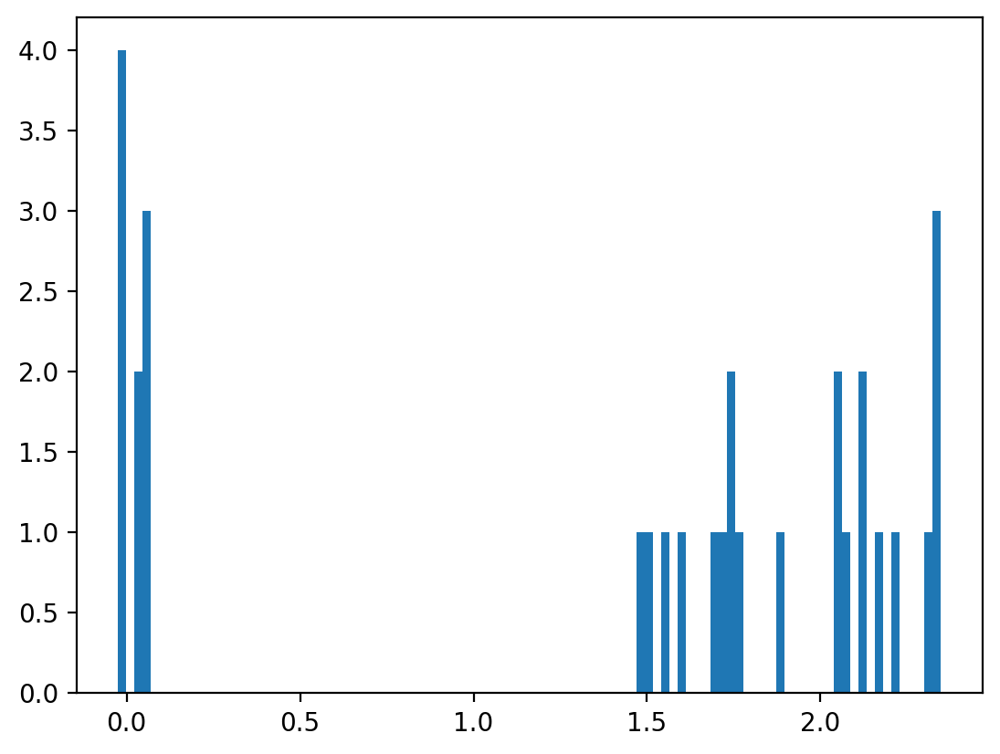

In [23]:
_ = plt.hist(np.log10(ccs), bins=100)
print(samples_cold.shape[0]-burnin)
sort_idx = np.argsort(ccs)
for idx in sort_idx[:-30:-1]:
    print(par_names[idx], str(ccs[idx]))

/var/folders/2d/fgm3f5p925zb3hcy0_z3hjgm0000gn/T/ipykernel_71754/1275545563.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(i)


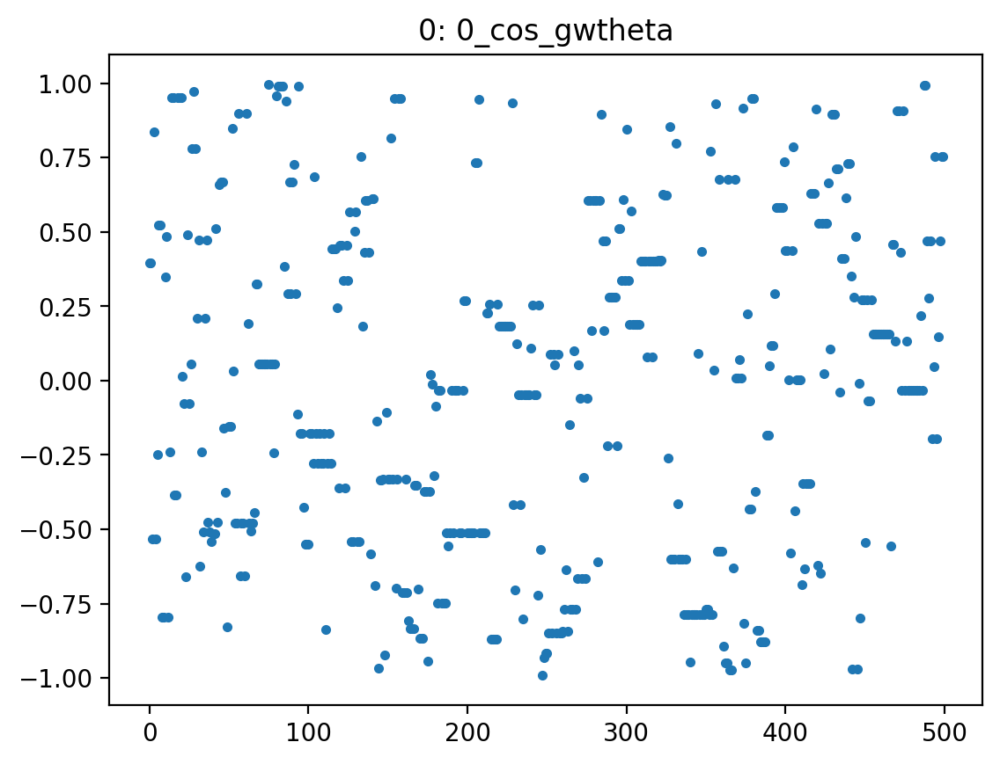

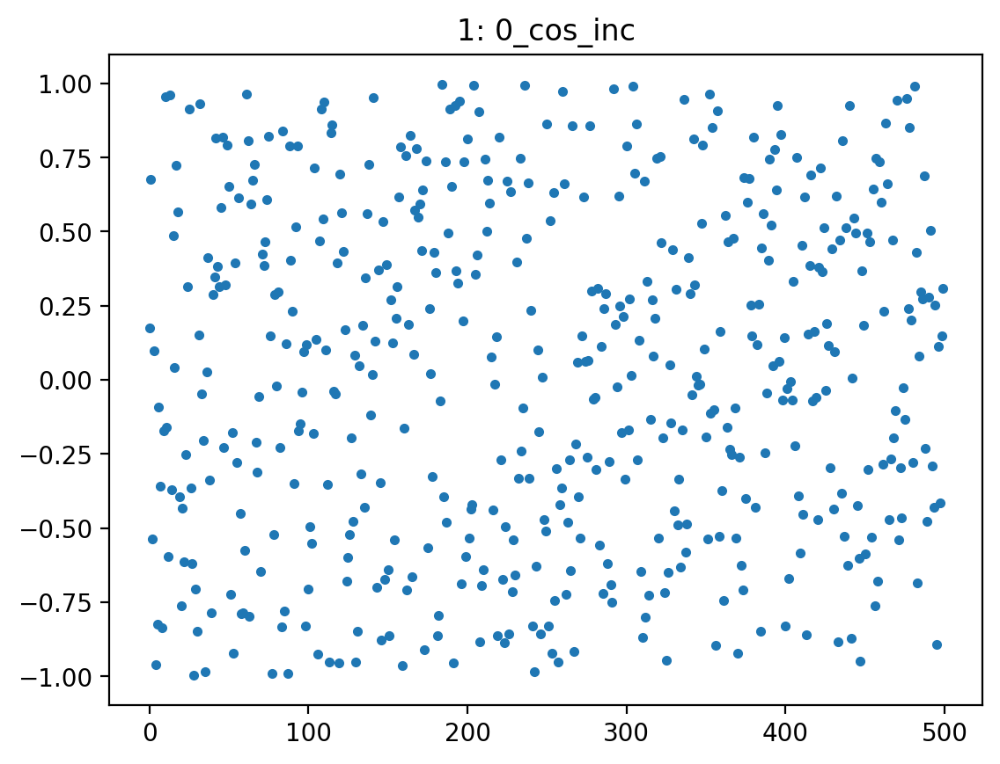

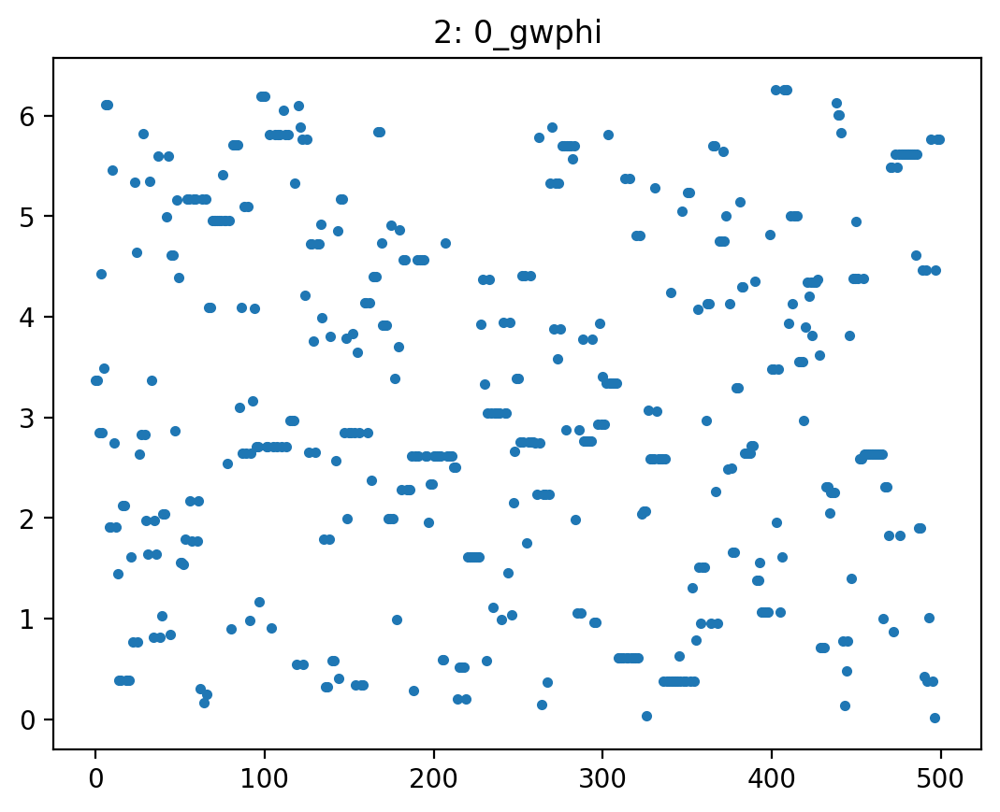

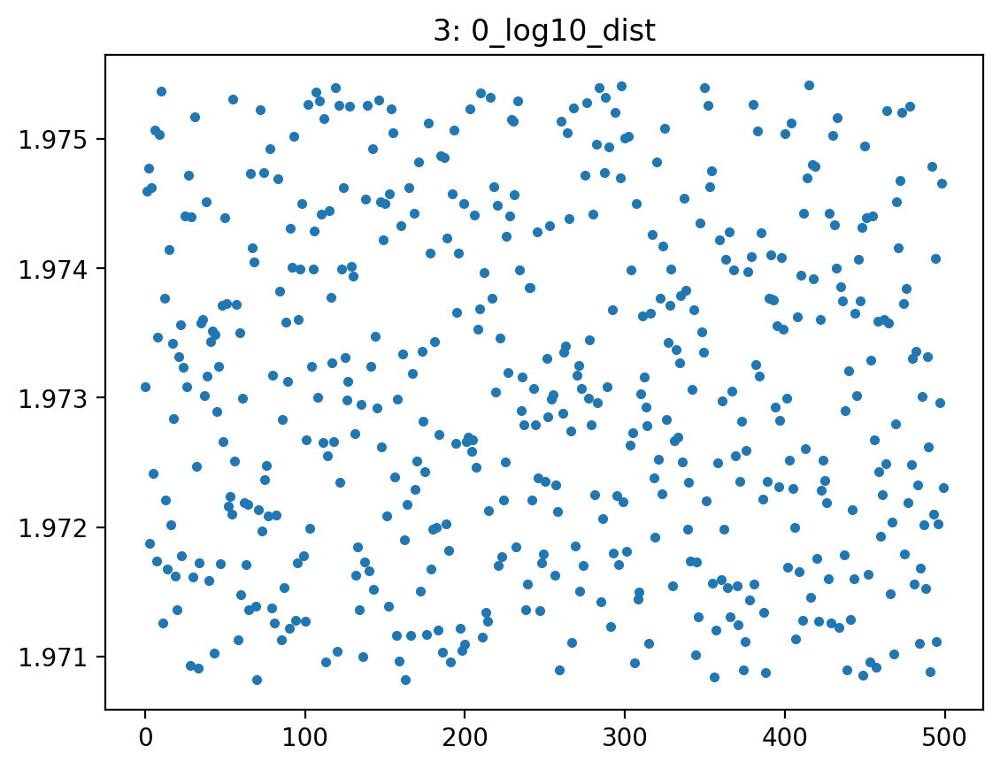

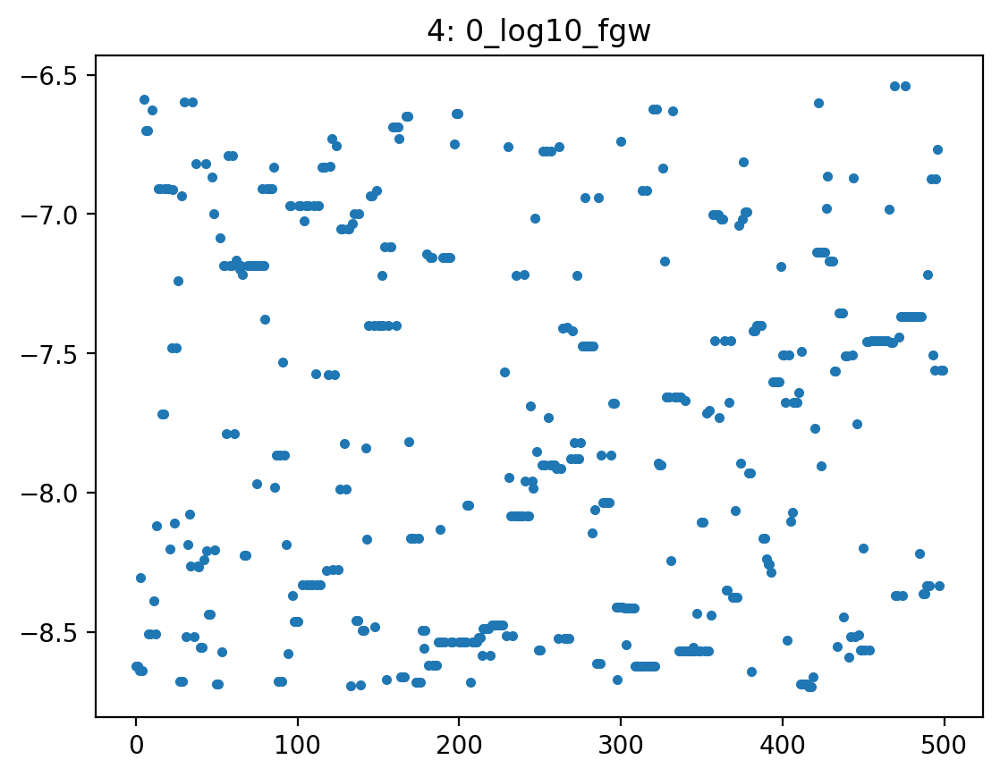

...

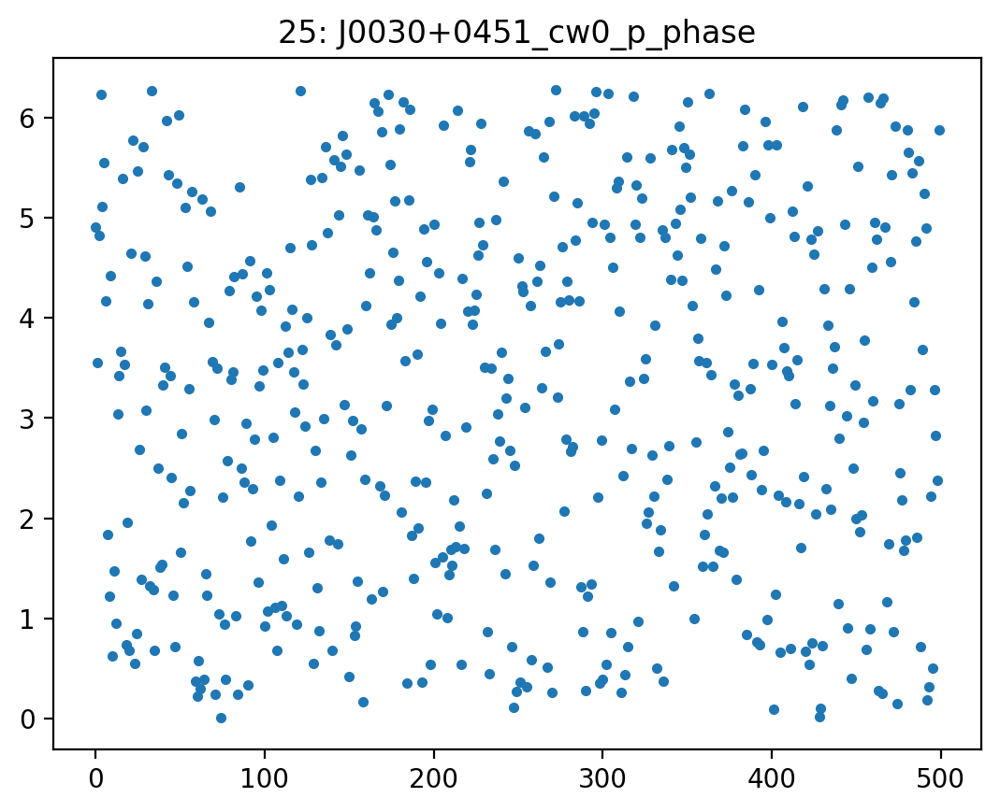

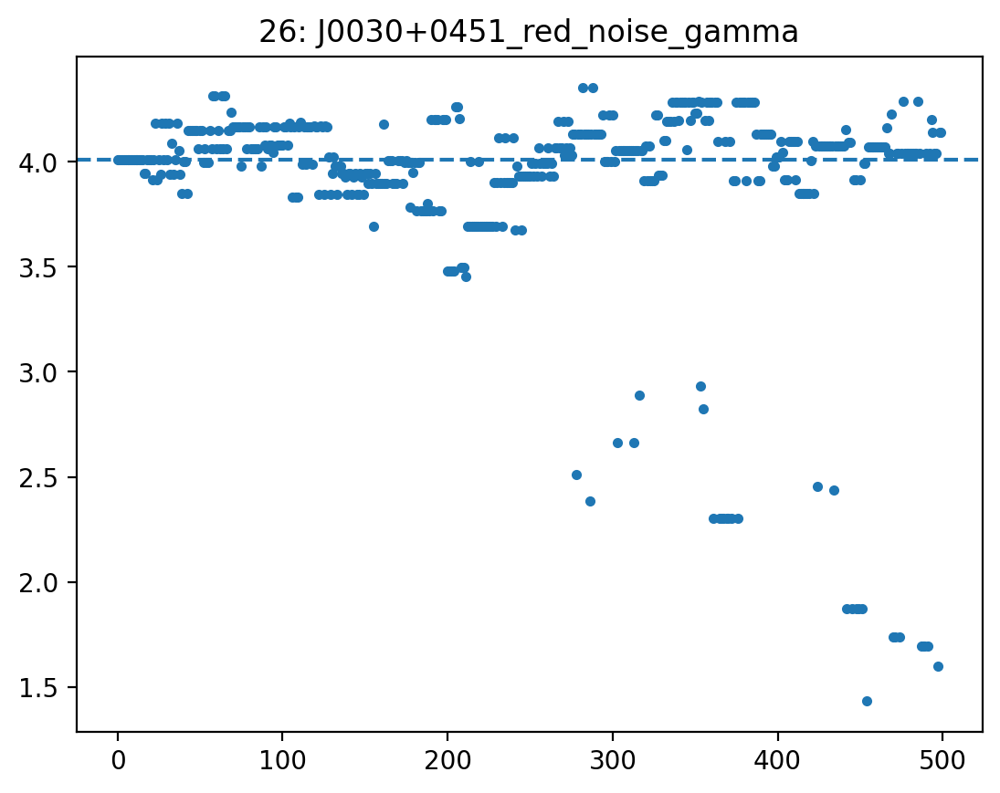

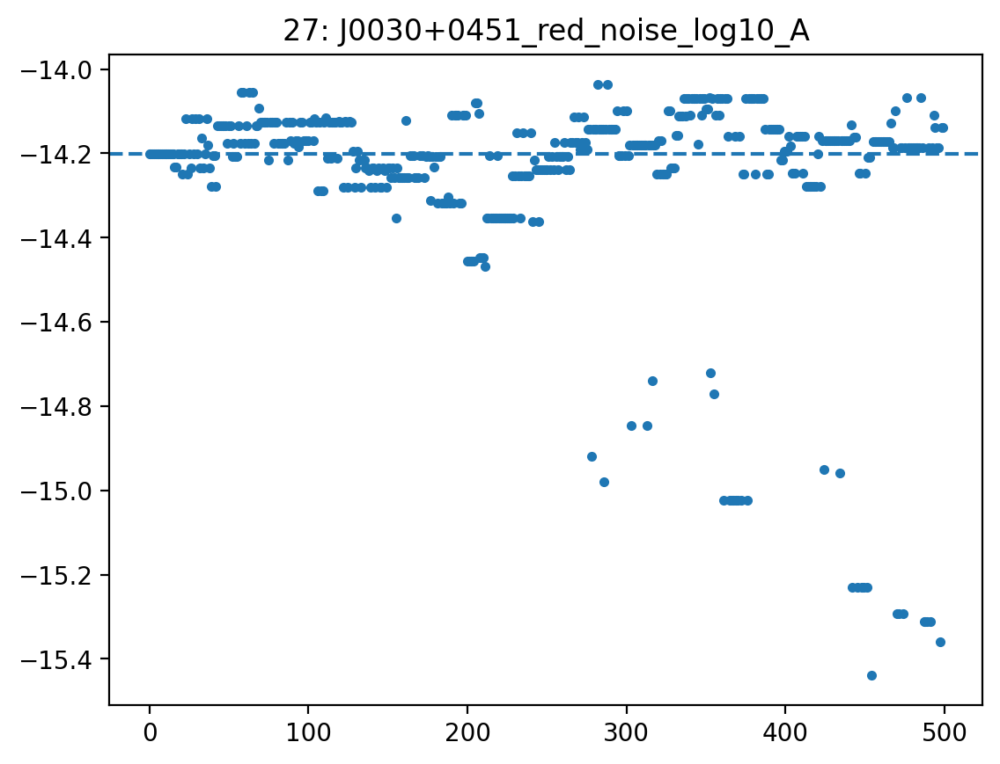

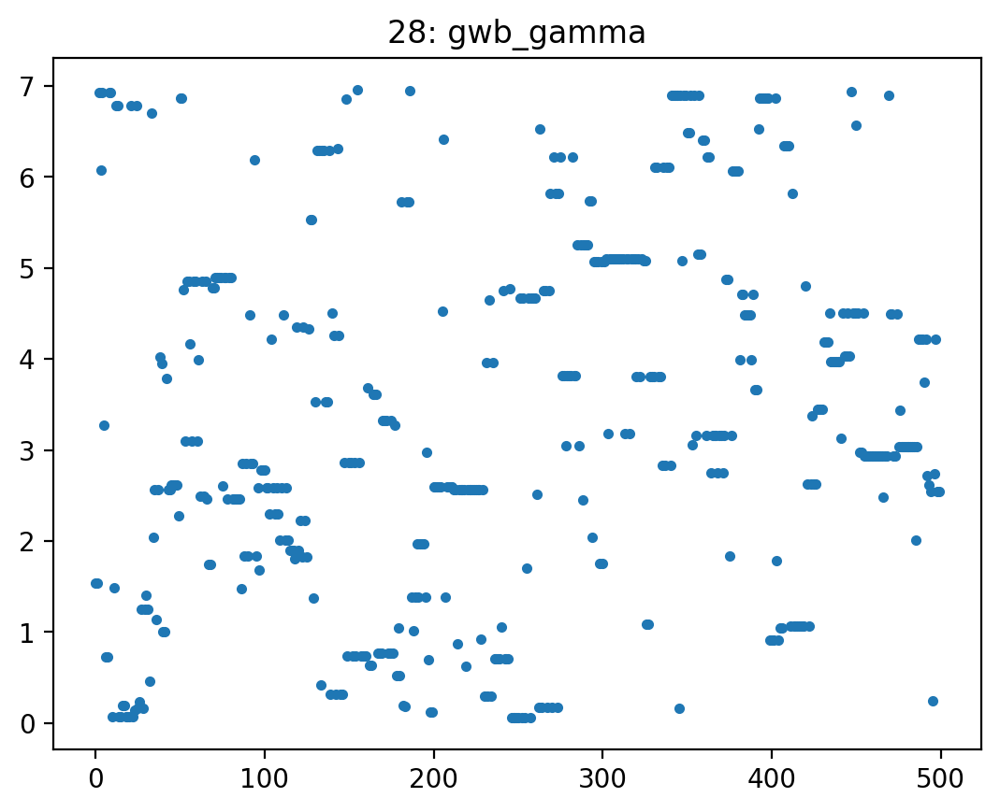

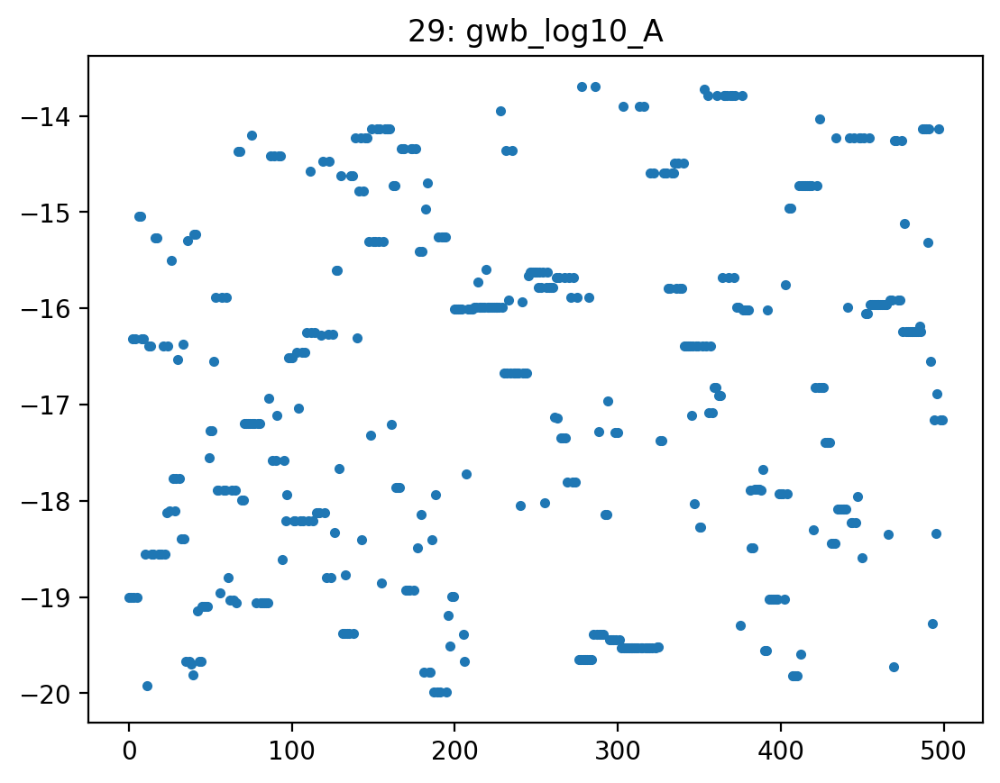

In [24]:
#plot trace of all parameters
for i, par in enumerate(par_names):
    plt.figure(i)
    plt.plot(samples_cold[::100,i], ls='', marker='.')
    plt.gca().axhline(xxx[par], ls='--')

    plt.title(str(i) + ": " + par)

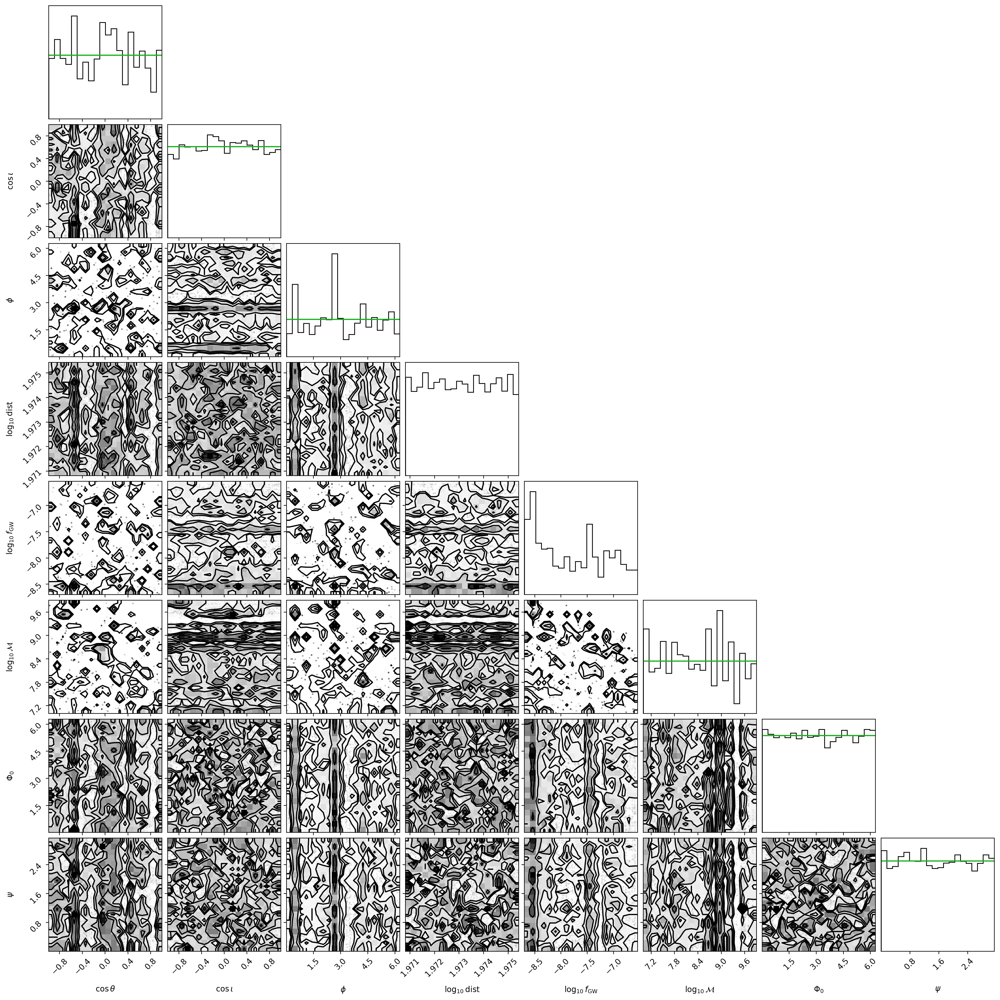

In [30]:
#corner plot of parameters common to all pulsars
corner_mask = [0, 1, 2, 3, 4, 5, 6, 7]
par_keys = ["0_cos_gwtheta", "0_cos_inc", "0_gwphi", "0_log10_dist", "0_log10_fgw",
          "0_log10_mc", "0_phase0", "0_psi"]
labels = [r"$\cos \theta$", r"$\cos \iota$", r"$\phi$", r"$\log_{10} {\rm dist}$", r"$\log_{10} f_{\rm GW}$",
           r"$\log_{10} {\cal M}$", r"$\Phi_0$", r"$\psi$"]


#set ranges
ranges = [(-1,1), (-1,1), (0,2*np.pi), (1.97, 1.98), (np.log10(3.5e-9),-7), (7,10), (0,2*np.pi), (0,np.pi) ]

#set burnin and thinning
burnin = 100
thin = 10

truth = [xxx[key] for key in par_keys]
fig = corner.corner(samples_cold[burnin::thin,corner_mask], labels=labels, #show_titles=True, quantiles=[0.16, 0.5, 0.84],
                    truths=truth, range=None, #range=ranges, 
                    hist_kwargs={"density":True})

#plot priors over 1D posteriors
for i, ax in enumerate(fig.axes):
    if i==0 or i==(len(labels)+1): #cos inc and cos theta
        Xs = np.linspace(-1,1)
        ax.plot(Xs, Xs*0+1/2, color="xkcd:green")
    elif i==2*(len(labels)+1) or i==6*(len(labels)+1): #gwphi and phase0
        Xs = np.linspace(0,2*np.pi)
        ax.plot(Xs, Xs*0+1/(2*np.pi), color="xkcd:green")
    elif i==3*(len(labels)+1): #log10_fgw
        Xs = np.linspace(np.log10(3.5e-9), -7.0)
        ax.plot(Xs, Xs*0+1/(-7-np.log10(3.5e-9)), color="xkcd:green")
    elif i==4*(len(labels)+1): #log10_A
        Xs = np.linspace(-18, -11)
        ax.plot(Xs, Xs*0+1/7, color="xkcd:green")
    elif i==5*(len(labels)+1): #log10_M_ch
        Xs = np.linspace(7, 10)
        ax.plot(Xs, Xs*0+1/3, color="xkcd:green")
    elif i==7*(len(labels)+1): #psi
        Xs = np.linspace(0,np.pi)
        ax.plot(Xs, Xs*0+1/np.pi, color="xkcd:green")

B1855+09
B1937+21


B1953+29
J0023+0923


J0030+0451


<Figure size 640x480 with 0 Axes>

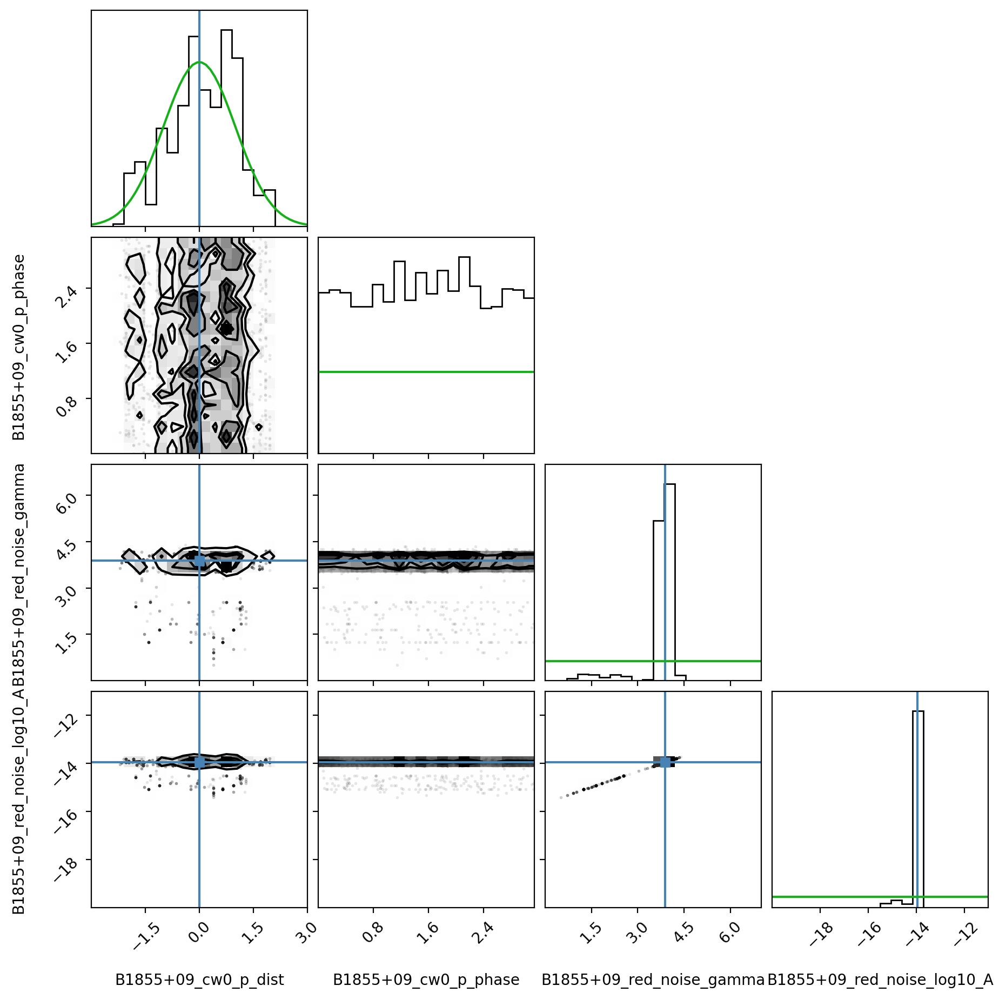

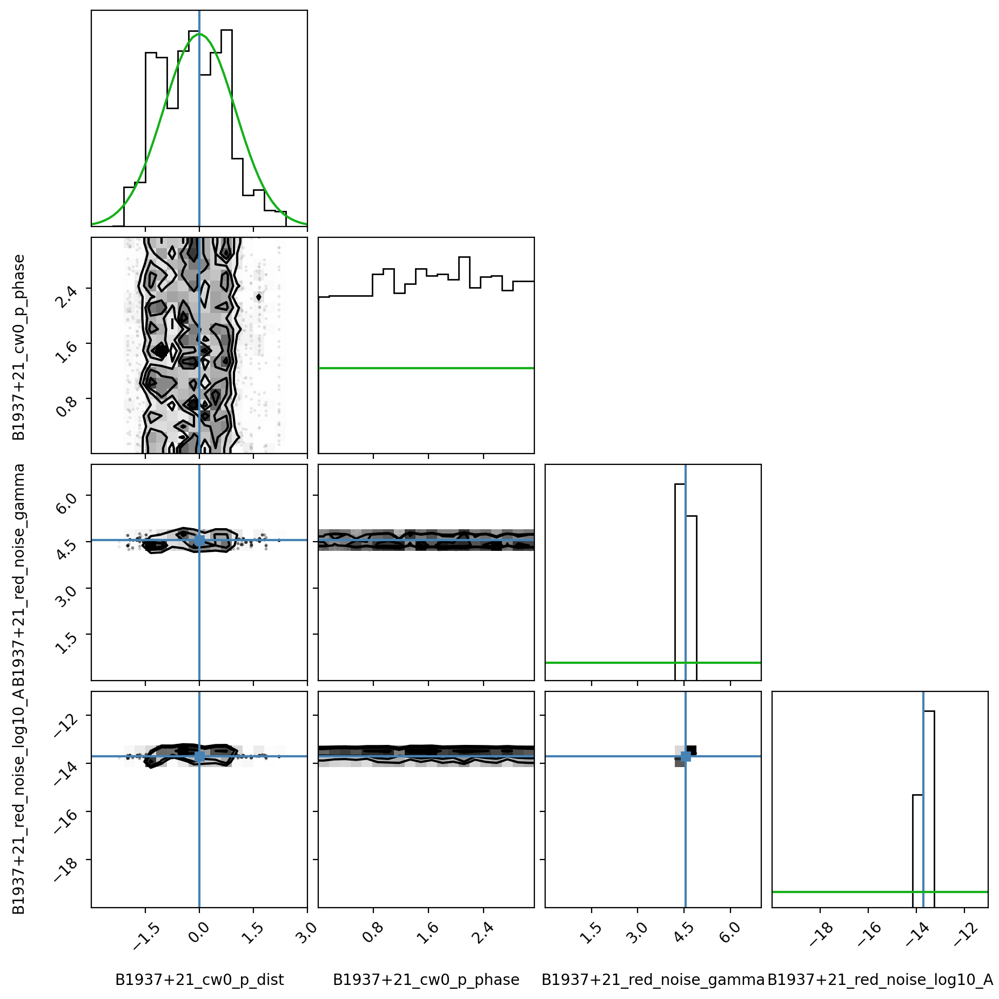

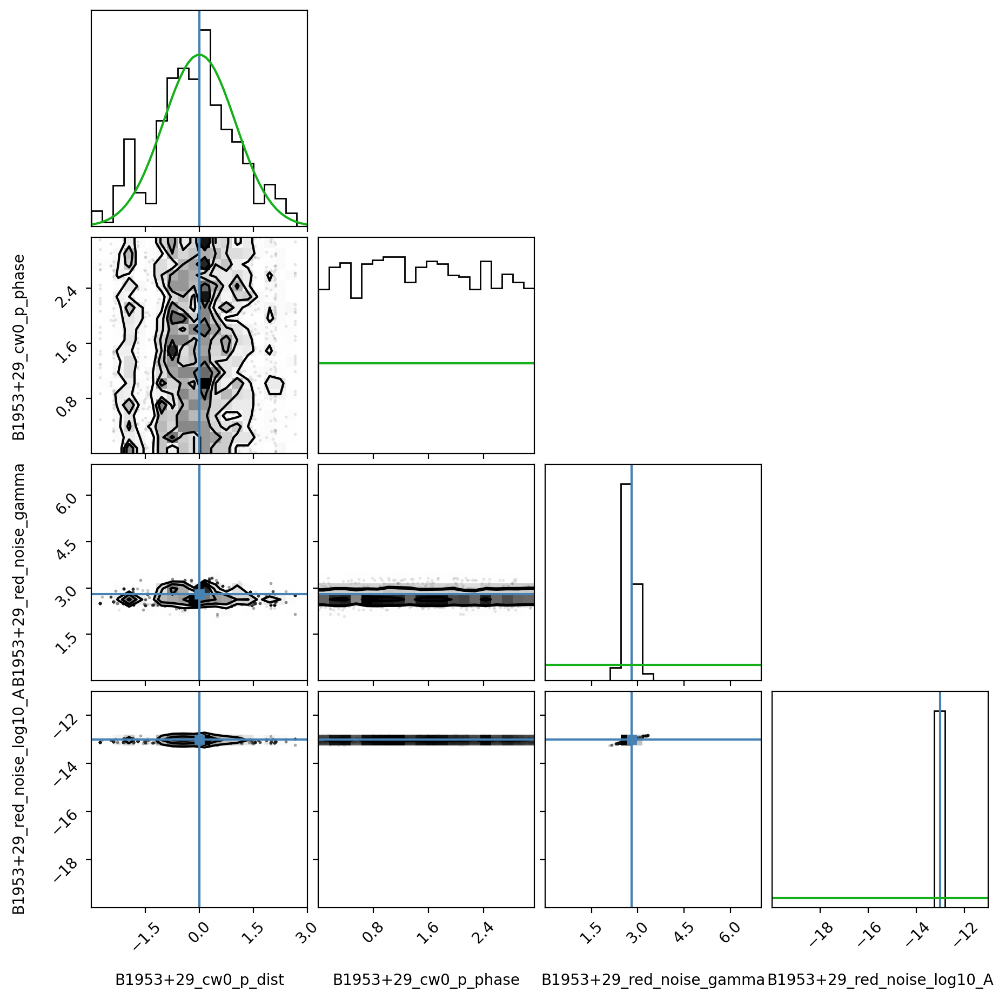

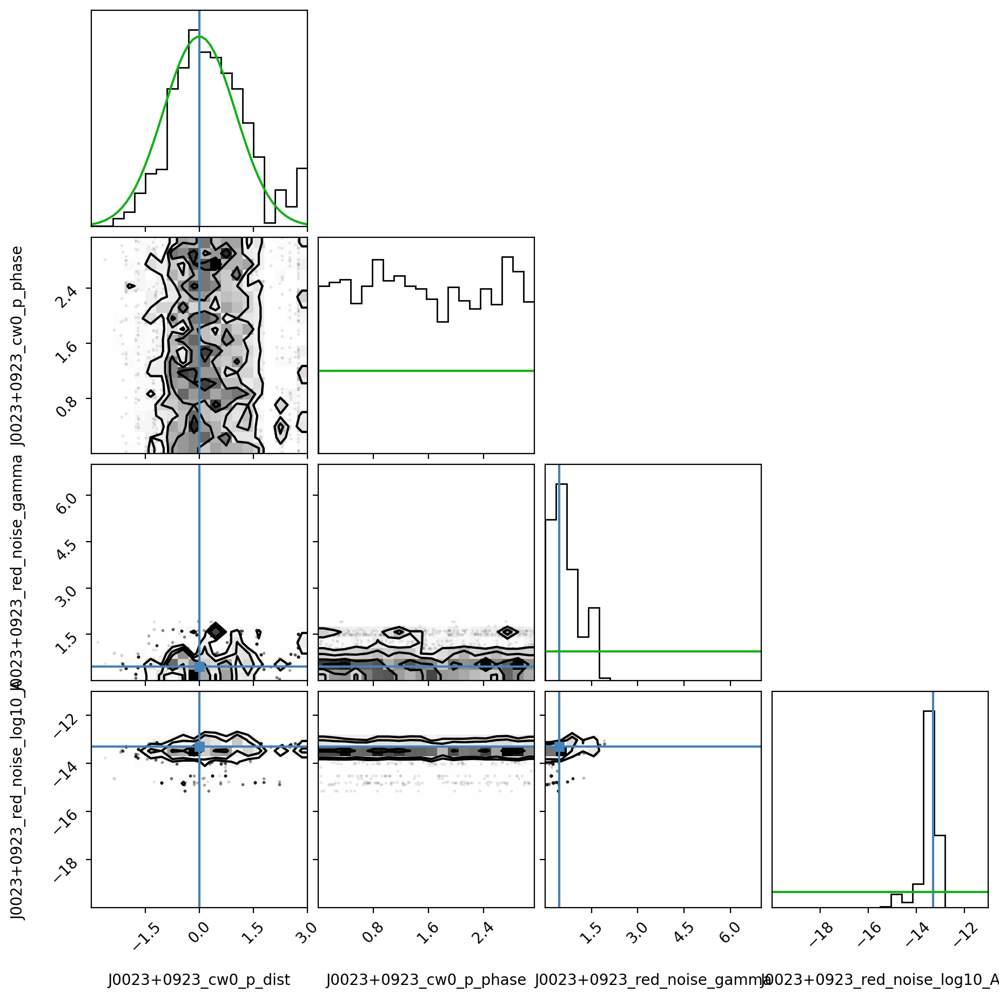

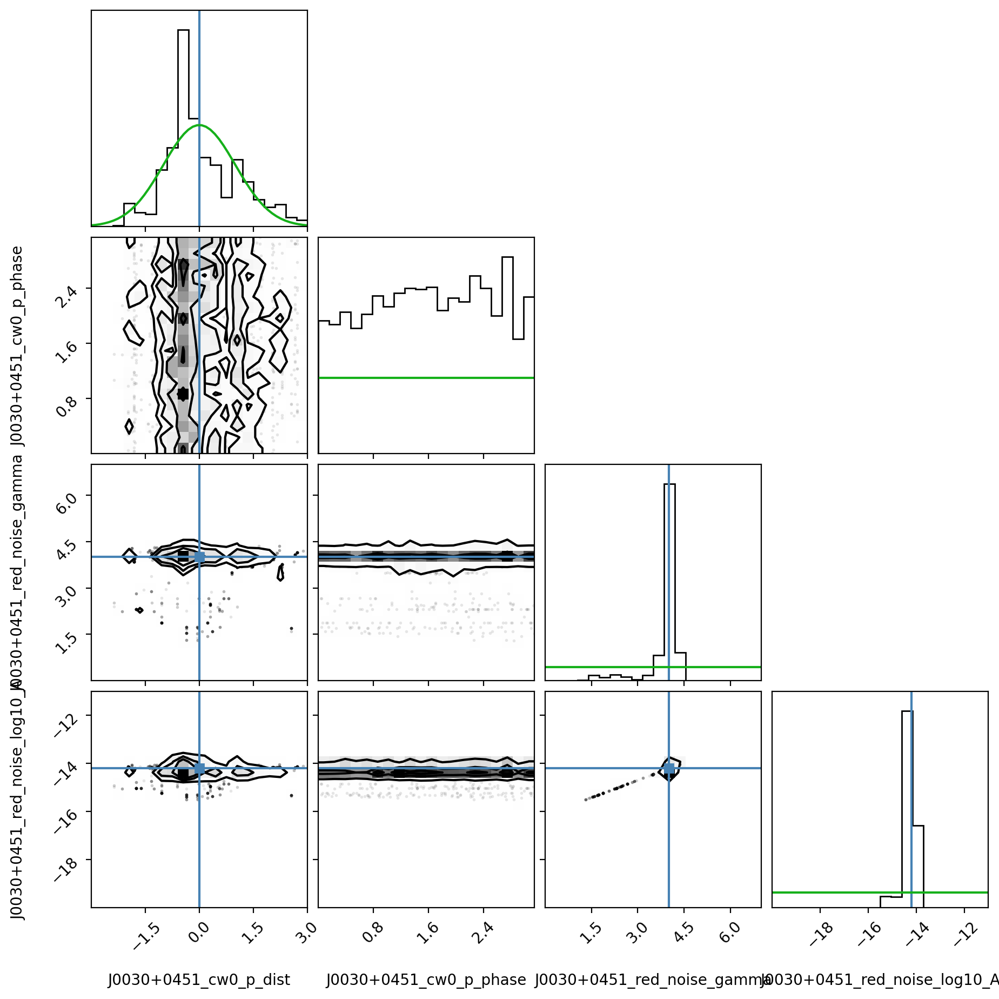

In [31]:
#corner plots for pulsar specific parameters

for I, psr in enumerate(psrs[:]):
    plt.figure(I)
    print(psr.name)
    corner_mask = [8+I*4, 9+I*4, 10+I*4, 11+I*4]
    labels = ["{0}_cw0_p_dist".format(psr.name), "{0}_cw0_p_phase".format(psr.name),
              "{0}_red_noise_gamma".format(psr.name), "{0}_red_noise_log10_A".format(psr.name)]
    #ranges = [(-3,3), (0, 2*np.pi), 0.999, 0.999]
    ranges = [(-3,3), (0, np.pi), (0,7), (-20,-11)]

    burnin = 100
    thin = 10

    truth = [xxx[key] for key in labels]
    fig = corner.corner(samples_cold[burnin::thin,corner_mask], labels=labels,
                        truths=truth, range=ranges, hist_kwargs={"density":True})

    Xs = np.linspace(0,2*np.pi)
    Ys = np.linspace(-3.0,3.0)
    Zs = np.linspace(0.0,7.0)
    Qs = np.linspace(-20.0, -11.0)

    for i, ax in enumerate(fig.axes):
        if i%(len(labels)+1)==0:
            if i%(4*(len(labels)+1))==0: #psr distance
                ax.plot(Ys, norm.pdf(Ys), color="xkcd:green")
            elif i%(4*(len(labels)+1))==1*(len(labels)+1): #psr phase
                ax.plot(Xs, Xs*0+1/(2*np.pi), color="xkcd:green")
            elif i%(4*(len(labels)+1))==2*(len(labels)+1): #rn gamma
                ax.plot(Zs, Zs*0+1/7.0, color="xkcd:green")
            elif i%(4*(len(labels)+1))==3*(len(labels)+1): #rn log_10_A
                ax.plot(Qs, Qs*0+1/9.0, color="xkcd:green")
        #print(ax.set_xlabel(i))

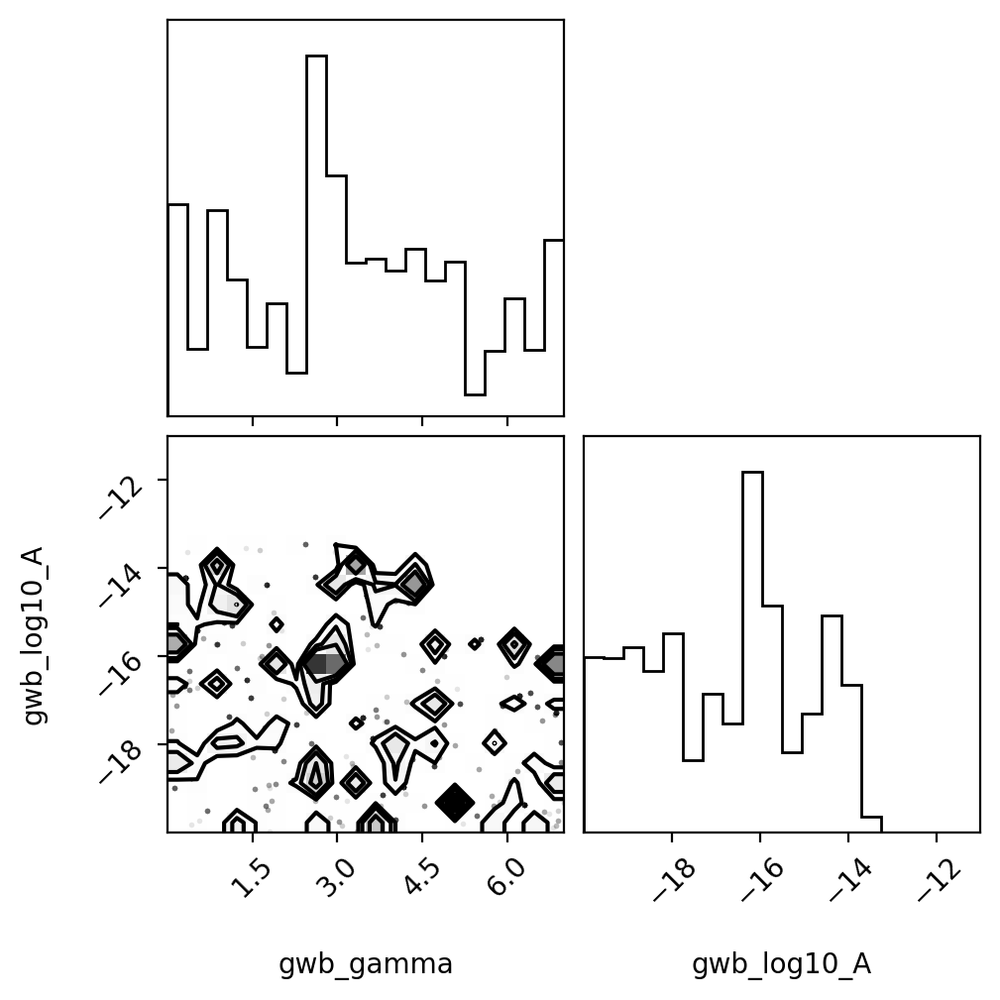

In [33]:
#gwb
corner_mask = [-2, -1]
labels = ["gwb_gamma", "gwb_log10_A"]
#ranges = [0.999, ]*8
ranges = [(0,7), (-20,-11)]

burnin = 0
#burnin = 50_000
# burnin = 100_000
thin = 10

truth = [xxx[key] for key in labels]
fig = corner.corner(samples_cold[burnin::thin,corner_mask], labels=labels,
                    truths=truth, range=ranges, hist_kwargs={"density":True})

## UL vs. frequency

In [4]:
official_11yr_skyavg = np.loadtxt("../data/11yr_ul_skyavg_DE436.txt")

1
950000
3.5255192563008488e-09 9.911633809173201e-08
[3.52551926e-09 7.05103851e-09 1.05765578e-08 1.41020770e-08
 1.76275963e-08 2.11531155e-08 2.46786348e-08 2.82041541e-08
 3.17296733e-08 3.52551926e-08 3.87807118e-08 4.23062311e-08
 4.58317503e-08 4.93572696e-08 5.28827888e-08 5.64083081e-08
 5.99338274e-08 6.34593466e-08 6.69848659e-08 7.05103851e-08
 7.40359044e-08 7.75614236e-08 8.10869429e-08 8.46124622e-08
 8.81379814e-08 9.16635007e-08 9.51890199e-08 9.87145392e-08]
[5.288278884451273e-09, 8.813798140752122e-09, 1.2339317397052971e-08, 1.586483665335382e-08, 1.939035590965467e-08, 2.2915875165955517e-08, 2.6441394422256365e-08, 2.9966913678557216e-08, 3.349243293485806e-08, 3.701795219115892e-08, 4.054347144745976e-08, 4.4068990703760606e-08, 4.759450996006146e-08, 5.112002921636231e-08, 5.464554847266315e-08, 5.817106772896401e-08, 6.169658698526485e-08, 6.522210624156571e-08, 6.874762549786655e-08, 7.22731447541674e-08, 7.579866401046824e-08, 7.93241832667691e-08, 8.284970

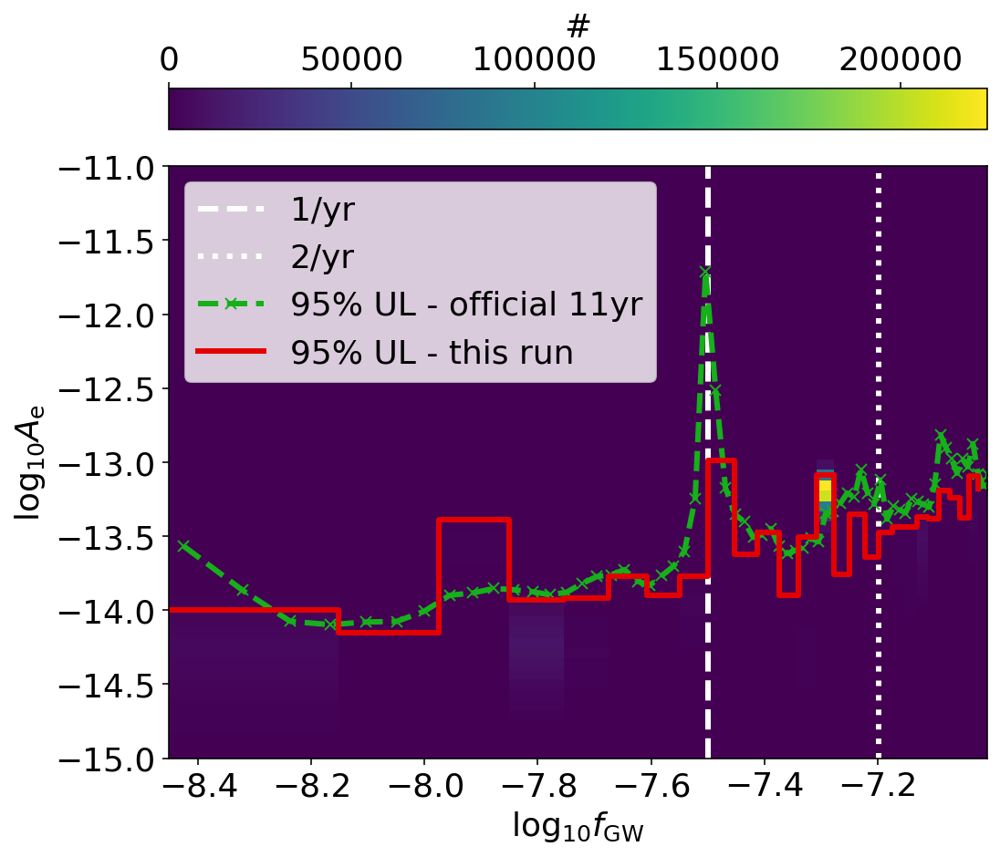

In [11]:
%%time
plt.rcParams.update({'font.size': 18})

#burnin = 100_000
burnin = 50_000
thin=1
#thin = 10*int(np.max([ccs[3],ccs[4]]))
print(thin)

log10_fgws = samples_cold[burnin::thin,3]
log10_hs = samples_cold[burnin::thin,4]
print(log10_fgws.size)


"""f_bincenters = official_11yr_skyavg[1:67,0]
#f_bincenters = official_11yr_skyavg[1:8,0]
print(f_bincenters)
f_bins = []
for i in range(f_bincenters.shape[0]-1):
    f_bins.append(f_bincenters[i]-(f_bincenters[i+1]-f_bincenters[i])/2)
f_bins.append(f_bincenters[-1]-(f_bincenters[-1]-f_bincenters[-2])/2)
f_bins.append(f_bincenters[-1]+(f_bincenters[-1]-f_bincenters[-2])/2)
print(f_bins)"""

f_min = 10**np.min(samples_cold[::10,3])
f_max = 10**np.max(samples_cold[::10,3])
print(f_min, f_max)
#f_bins = np.linspace(f_min, f_max, int(f_max/f_min))
f_bins = np.arange(1,int(f_max/f_min)+1)*f_min
print(f_bins)

f_bincenters = []
for i in range(f_bins.size-1):
    f_bincenters.append((f_bins[i+1]+f_bins[i])/2)
print(f_bincenters)

log10_h_bins = np.linspace(-18,-11,100)

plt.figure(figsize=(8,7))
#h, xedges, yedges, _ = plt.hist2d(log10_fgws, log10_hs, bins=50, range=[[np.log10(3.5e-9),-7],[-18,-11]])
#h, xedges, yedges, _ = plt.hist2d(log10_fgws, log10_hs, bins=100, range=[[np.log10(3.5e-9),-7],[-15.5,-11]],
#                                  weights=log10_fgws*0+1/60.0)
h, xedges, yedges, _ = plt.hist2d(log10_fgws, log10_hs, bins=[np.log10(f_bins), log10_h_bins])

#make bin centers
bincenters = []
for i in range(xedges.size-1):
    bincenters.append((xedges[i+1]+xedges[i])/2)
bincenters = np.array(bincenters)

#print(xedges)
#print(bincenters)

freq_idx = np.digitize(log10_fgws, xedges)
#plt.scatter(log10_fgws[np.where(freq_idx==1)], log10_hs[np.where(freq_idx==1)])

N_bootstrap = 1000
#N_resample = 100

UL_freq = np.zeros(bincenters.size)
#UL_freq_reweight = np.zeros(bincenters.size)
#UL_freq_reweight_low = np.zeros(bincenters.size)
#UL_freq_reweight_high = np.zeros(bincenters.size)
UL_freq_error = np.zeros(bincenters.size)
for i in range(bincenters.size):
    print('---')
    print(i)
    hs = 10**log10_hs[np.where(freq_idx==i+1)]
    if hs.size==0:
        UL_freq[i] = 0.0
        continue
    
    UL_freq[i] = np.percentile(hs, 95)

    N_inbin = hs.shape[0]
    N_resample = int(N_inbin)

    print(N_inbin)

    #N_batch = int(N_inbin**(1/5))
    N_batch = 10
    if N_inbin<10*N_batch:
        N_batch=1
    print(N_batch)
    
    hs_batches = []
    for K in range(N_batch):
        hs_batches.append(hs[K*int(N_inbin/N_batch):(K+1)*int(N_inbin/N_batch)])

    ULs = np.zeros(N_bootstrap)
    for k in range(N_bootstrap):
        IDXS = np.random.choice(N_batch, size=N_batch, replace=True)
        hs_shuffle = np.block([hs_batches[J] for J in IDXS])
        ULs[k] = np.percentile(hs_shuffle, 95)
    
    UL_freq_error[i] = np.std(ULs)
    

plt.gca().axvline(x=-np.log10(3600*24*365.24), ls='--', lw=3, color='white', label='1/yr')
plt.gca().axvline(x=-np.log10(3600*24*365.24*0.5), ls=':', lw=3, color='white', label='2/yr')
#plt.plot(bincenters, UL_freq, ls='-', lw=3, marker='.', color="xkcd:red", label="95% UL")
#plt.errorbar(bincenters, np.log10(UL_freq), ls='-', lw=3, marker='x', color="xkcd:red",
#             label="95% UL - this run - old", alpha=0.3)
plt.errorbar(xedges[:-1], np.log10(UL_freq), ls='-', lw=3, color="xkcd:red",
             drawstyle='steps-post', label="95% UL - this run")
#plt.fill_between(bincenters, UL_freq_reweight_low, UL_freq_reweight_high,
#                 color="xkcd:red", alpha=0.3, label="95% UL")
plt.plot(np.log10(official_11yr_skyavg[1:67,0]), np.log10(official_11yr_skyavg[1:67,1]),
         ls='--', lw=3, marker='x', color="xkcd:green", label="95% UL - official 11yr")
#plt.plot(np.log10(official_11yr_skyavg[:,0]), np.log10(official_11yr_skyavg[:,2]),
#         ls='--', lw=3, marker='.', color="xkcd:purple", label="95% UL - official2")
plt.ylim(-15,-11)
#plt.xlim(-8.75, -7.0)
plt.xlabel(r"$\log_{10} f_{\rm GW}$")
plt.ylabel(r"$\log_{10} A_{\rm e}$")

cbar = plt.colorbar(location='top')
cbar.set_label('#')

plt.legend(loc=2)

plt.tight_layout()  # otherwise the right y-label is slightly clipped
#plt.savefig("Figs/UL_vs_freq.png", dpi=300)
#plt.savefig("Figs/UL_vs_freq_new_seed.png", dpi=300)

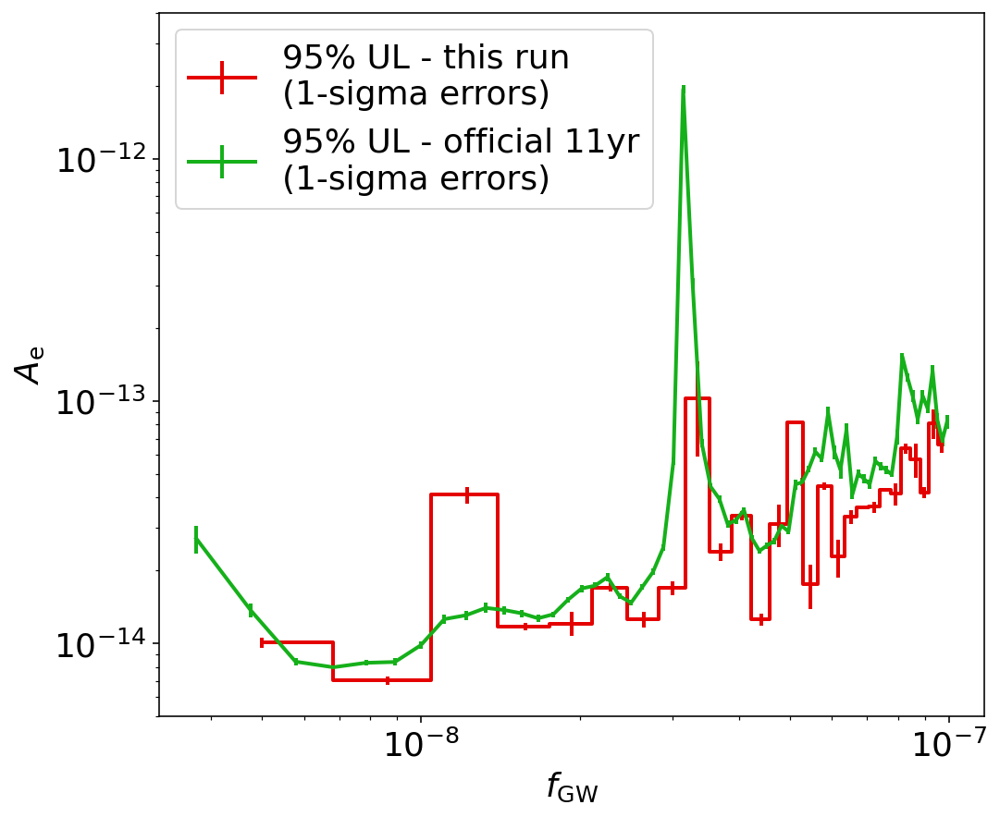

In [18]:
plt.figure(figsize=(8,7))

plt.errorbar(10**bincenters, UL_freq, yerr=UL_freq_error,
             ls='', lw=2, marker='.', alpha=0., color="xkcd:red")

plt.errorbar(10**xedges[:-1], UL_freq, drawstyle='steps-post',
             ls='-', lw=2, marker='', alpha=1.0, color="xkcd:red", label="95% UL - this run\n(1-sigma errors)")

plt.errorbar(official_11yr_skyavg[1:67,0], official_11yr_skyavg[1:67,1],
             yerr=official_11yr_skyavg[1:67,2],
             ls='-', lw=2, marker='', color="xkcd:green", label="95% UL - official 11yr\n(1-sigma errors)")

plt.xscale('log')
plt.yscale('log')
plt.ylim(5e-15,4e-12)
plt.xlabel(r"$f_{\rm GW}$")
plt.ylabel(r"$A_{\rm e}$")

plt.legend(loc=2)